# Reproducing Brégère & Bessa (2020): CVAE tariff-impact simulator
*Simulating Tariff Impact in Electrical Energy Consumption Profiles With Conditional Variational Autoencoders*, IEEE Access 8:131949.

**What the paper does.** It clusters the London households on the 2013 dynamic time-of-use trial (Low Carbon London, LCL) by their daily consumption profile under each price level (shape and price response). It then trains one conditional VAE (CVAE) per cluster to generate daily load profiles from the tariff schedule, the weather and the calendar, and compares it with a GAM-based generator. This is the simulator our proposal plans to use in Step 2.

**How we tested it.**
- **Track A, the authors' data:** their prepared cluster series and train/test split (from their GitHub), with our re-implementations of both generators. The CVAE is a faithful PyTorch port of their code, with one deliberate change: each of the 50 training runs gets its own random seed, as the paper intends. The GAM, the clustering and the scores are our own, because the authors did not publish that code.
- **Track B, our data:** everything rebuilt from the raw LCL files, ERA5 temperatures, `Tariffs.xlsx` and our own run of their clustering.

Independent checkers re-tested every result (`outputs/verify/`). Heavy computation lives in `scripts/`; this notebook only reads its outputs.

**Bottom line.**
- **What reproduces, on both tracks:** the paper's accuracy results (RMSE and variogram score in Fig. 4). Also its qualitative claims: CVAE samples are too narrow, GAM samples too wide, and responsiveness differs between clusters (in our runs one cluster, 16% of households, carries most of the response).
- **The CVAE's "side" and "rebound" effects are not in the consumption data.** These are the paper's headline contributions. The side effect most likely reflects the longer tariff blocks the CVAE was trained on.
- **The CVAE is nearly deterministic.** Its latent variable collapses. Lowering the KL weight revives it only at η ≤ 0.03, and even then the samples stay too narrow while the mean profile gets 12-61% less accurate.
- **The energy-score comparison and the "13%" RMSE gap contradict the paper's own figures.**

In [ ]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7",
                     "axes.axisbelow": True, "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
                     "ytick.color": "#52514e"})
BLUE, ORANGE, AQUA, INK, MUTED, SHADE = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#898781", "#f0efec"
J = lambda path: json.load(open(path, encoding="utf-8"))
x48 = (np.arange(48) - 0.5) / 2   # slot h = the half-hour ENDING at h/2 h GMT (LCL convention); drawn at its midpoint

## 1. Scorecard
Clusters are numbered 0-3 as in the paper. *A* = authors' data, *B* = our data. Paper values for Fig. 4 were read exactly from the PDF's vector graphics.

Terms: **spread/skill** = ensemble spread ÷ error of the ensemble mean (1 = calibrated). **ARI** = adjusted Rand index (1 = same partition). **CH** = Calinski-Harabasz index.

In [ ]:
rows = [
 ("Data", "ToU households with >95% of 2013 data", "1,007", "their 1,007 identified exactly (aggregate: mean abs. diff. 3e-8 kWh, max 2.4e-4)", "rule keeps 1,032; their 1,007 are a subset", "partial"),
 ("Data", "3 temperature PCs explain ~98%, 4 consumption PCs >80%", "98% / >80%", "98.9% / 88-95%", "99.2% / 87-96%", "reproduced"),
 ("Clustering", "Causality model + NMF + k-medoids gives clusters of 325/295/229/158", "325/295/229/158", "recovered exactly from their data", "285/299/299/149 (ARI 0.58-0.66 vs theirs)", "partial"),
 ("Clustering", "Table 3 CH index, NMF ToU (raw / std / tariff slots)", "13,432 / 14,088 / 16,070", "13,433 / 14,076 / 16,055 *", "14,342 / 14,684 / 16,536 *", "reproduced *"),
 ("Clustering", "CH gain vs classical features (ToU, tariff slots)", "+128%", "n/a (their features clusters unpublished)", "+87% to +110%", "partial"),
 ("Clustering", "NMF clusters differ in shape, feature clusters in level (Fig. 2)", "qualitative", "yes", "yes", "reproduced"),
 ("Generators", "RMSE: GAM beats CVAE (Fig. 4, kWh)", "CVAE 0.018-0.024, GAM 0.015-0.019", "CVAE 0.018-0.024, GAM 0.014-0.019", "CVAE 0.017-0.025, GAM 0.013-0.019", "reproduced"),
 ("Generators", "Variogram score: GAM beats CVAE (Fig. 4)", "CVAE 5.9-10.5, GAM 3.8-6.0", "CVAE 5.6-9.0, GAM 3.8-5.8", "CVAE 5.3-9.8, GAM 3.6-6.1", "reproduced"),
 ("Generators", "Energy score: CVAE slightly better (Fig. 4)", "CVAE 0.134-0.170, GAM 0.135-0.169", "CVAE 0.113-0.153, GAM 0.074-0.094", "CVAE 0.107-0.162, GAM 0.068-0.094", "not reproduced"),
 ("Generators", "CVAE and GAM differ by 13% in RMSE (abstract)", "13% (its own Fig. 4: 19.5%)", "23.0%", "26.2%", "not reproduced"),
 ("Generators", "CVAE samples too narrow, GAM samples too wide", "qualitative", "spread/skill 0.08-0.13 vs 1.37-1.54", "0.08-0.14 vs 1.30-1.55", "reproduced"),
 ("Generators", "CVAE profiles smooth, GAM erratic, real ones in between", "qualitative", "yes", "yes", "reproduced"),
 ("Tariff effects", "Low raises and High lowers use, both generators", "stated generally (its own Fig. 8: CVAE Low up only in cl. 3; cl. 0 about 0)", "GAM: yes. CVAE: High down 4/4 (cl. 0 -0.3%), Low up in cl. 1, 3 only", "GAM: yes. CVAE: High down 3/4, Low up in cl. 1, 3 only", "partial"),
 ("Tariff effects", "CVAE side effect: High drop starts before, ends after the window (paper: real behaviour)", "'a little' (its Fig. 8: 1-5 h early, to midnight)", "CVAE: yes in cl. 1-3; data: no drop before or after", "CVAE: yes in cl. 1-3; data: no drop before or after", "partial (model only)"),
 ("Tariff effects", "CVAE rebound: less use after morning Low, more before evening High", "qualitative", "CVAE: evening dip 3/4, afternoon rise 2/4 (<= 2%); data: neither, only a short pre-load before evening High in cl. 3", "CVAE: evening dip 4/4, afternoon rise 1/4; data: no post-Low drop, pre-High rise in cl. 3", "not reproduced"),
 ("Tariff effects", "Responsiveness differs by cluster", "qualitative", "data (matched days): cl. 3 Low +45%, High -29%; others 2-6%", "data (matched days): cl. 3 Low +45%, High -24%; others 2-5%", "reproduced"),
]
card = pd.DataFrame(rows, columns=["Area", "Paper claim", "Paper", "A: authors' data", "B: our data", "Verdict"])
display(card.style.hide(axis="index").set_properties(**{"text-align": "left", "vertical-align": "top"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))
print(card.Verdict.str.extract(r"^(reproduced|partial|not reproduced)")[0].value_counts().to_dict())
print("* Table 3 is matched only when the CH index uses non-squared Euclidean distances and weights each cluster's\n"
      "  between-cluster distance by its size; eqs. 3-5 as printed give 6.7 / 8.0 / 12.7.")

Area,Paper claim,Paper,A: authors' data,B: our data,Verdict
Data,ToU households with >95% of 2013 data,"1,007","their 1,007 identified exactly (aggregate: mean abs. diff. 3e-8 kWh, max 2.4e-4)","rule keeps 1,032; their 1,007 are a subset",partial
Data,"3 temperature PCs explain ~98%, 4 consumption PCs >80%",98% / >80%,98.9% / 88-95%,99.2% / 87-96%,reproduced
Clustering,Causality model + NMF + k-medoids gives clusters of 325/295/229/158,325/295/229/158,recovered exactly from their data,285/299/299/149 (ARI 0.58-0.66 vs theirs),partial
Clustering,"Table 3 CH index, NMF ToU (raw / std / tariff slots)","13,432 / 14,088 / 16,070","13,433 / 14,076 / 16,055 *","14,342 / 14,684 / 16,536 *",reproduced *
Clustering,"CH gain vs classical features (ToU, tariff slots)",+128%,n/a (their features clusters unpublished),+87% to +110%,partial
Clustering,"NMF clusters differ in shape, feature clusters in level (Fig. 2)",qualitative,yes,yes,reproduced
Generators,"RMSE: GAM beats CVAE (Fig. 4, kWh)","CVAE 0.018-0.024, GAM 0.015-0.019","CVAE 0.018-0.024, GAM 0.014-0.019","CVAE 0.017-0.025, GAM 0.013-0.019",reproduced
Generators,Variogram score: GAM beats CVAE (Fig. 4),"CVAE 5.9-10.5, GAM 3.8-6.0","CVAE 5.6-9.0, GAM 3.8-5.8","CVAE 5.3-9.8, GAM 3.6-6.1",reproduced
Generators,Energy score: CVAE slightly better (Fig. 4),"CVAE 0.134-0.170, GAM 0.135-0.169","CVAE 0.113-0.153, GAM 0.074-0.094","CVAE 0.107-0.162, GAM 0.068-0.094",not reproduced
Generators,CVAE and GAM differ by 13% in RMSE (abstract),13% (its own Fig. 4: 19.5%),23.0%,26.2%,not reproduced


{'reproduced': 8, 'partial': 5, 'not reproduced': 3}
* Table 3 is matched only when the CH index uses non-squared Euclidean distances and weights each cluster's
  between-cluster distance by its size; eqs. 3-5 as printed give 6.7 / 8.0 / 12.7.


## 2. Accuracy and calibration (paper Fig. 4)
- **RMSE and variogram score match the paper.** They are within 14% in every cluster on track A. On track B they match too, except in cluster 2 (up to 30% lower; our cluster 2 is a different, larger cluster, 299 vs 229 households). The GAM beats the CVAE on both scores everywhere. RMSE here is the root-mean over the 48 half-hours; eq. 12 as printed would be about 7× larger.
- **The energy score does not match.** The paper's energy-score panel also contradicts its own Figs. 6-7: on 1 Jan, cluster 3, its own CVAE samples score 0.26, above anything the panel shows. We therefore treat that panel as erroneous.
- In the figure, dots are medians over the 92 test days, bars are interquartile ranges, and black dashes are the paper's medians.

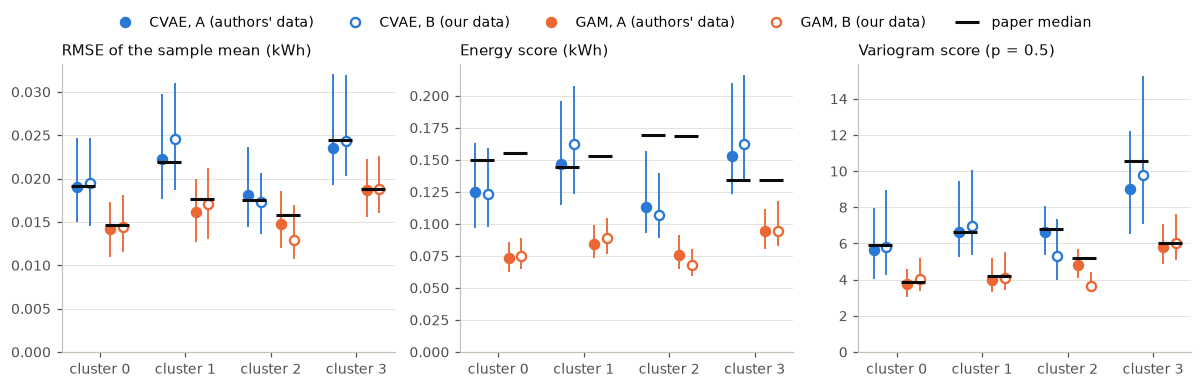

Medians over the 92 test days (columns = clusters 0-3):
                         0       1       2        3
score model source                                 
RMSE  CVAE  A       0.0191  0.0223  0.0181   0.0235
            B       0.0195  0.0246  0.0173   0.0244
      GAM   A       0.0142  0.0162  0.0148   0.0187
            B       0.0144  0.0171  0.0129   0.0188
      CVAE  paper   0.0191  0.0219  0.0176   0.0244
      GAM   paper   0.0146  0.0176  0.0158   0.0188
ES    CVAE  A       0.1248  0.1465  0.1129   0.1532
            B       0.1234  0.1624  0.1073   0.1622
      GAM   A       0.0736  0.0840  0.0761   0.0945
            B       0.0746  0.0889  0.0680   0.0945
      CVAE  paper   0.1500  0.1441  0.1696   0.1343
      GAM   paper   0.1551  0.1532  0.1687   0.1346
VG    CVAE  A       5.6338  6.6125  6.6181   9.0200
            B       5.8196  6.9700  5.3117   9.7723
      GAM   A       3.7561  3.9735  4.7888   5.8130
            B       4.0431  4.1110  3.6224   6.0548
      CV

In [ ]:
sc = pd.concat([pd.read_csv(f"outputs/track{t}/scores_long.csv").assign(track=t) for t in "AB"])
paper = pd.read_csv("outputs/verify/v-paper/fig4_exact_from_pdf_vectors.csv")
M = {"rmse_rootmean": ("RMSE", "RMSE of the sample mean (kWh)"), "es_split": ("ES", "Energy score (kWh)"),
     "vg_p05_ordered": ("VG", "Variogram score (p = 0.5)")}
q = sc.groupby(["track", "model", "cluster"])[list(M)].quantile([.25, .5, .75]).unstack()
LAB = {("cvae", "A"): "CVAE, A (authors' data)", ("cvae", "B"): "CVAE, B (our data)",
       ("gam", "A"): "GAM, A (authors' data)", ("gam", "B"): "GAM, B (our data)"}
off = {("cvae", "A"): -.27, ("cvae", "B"): -.12, ("gam", "A"): .12, ("gam", "B"): .27}
fig, axs = plt.subplots(1, 3, figsize=(11, 3.3))
tab = {}
for ax, (m, (pan, title)) in zip(axs, M.items()):
    for (mod, tr), dx in off.items():
        col, x = (BLUE if mod == "cvae" else ORANGE), np.arange(4) + dx
        ax.vlines(x, q.loc[(tr, mod), (m, .25)], q.loc[(tr, mod), (m, .75)], color=col, lw=1.2)
        ax.plot(x, q.loc[(tr, mod), (m, .5)], "o", ms=6, color=col, mfc=col if tr == "A" else "white", mew=1.5, label=LAB[(mod, tr)])
        tab[(pan, mod.upper(), tr)] = q.loc[(tr, mod), (m, .5)].to_numpy()
    for mod in ("cvae", "gam"):
        p = paper[(paper.panel == pan) & (paper.gen == mod.upper())].sort_values("cluster")["median"].to_numpy()
        ax.plot(np.arange(4) + (off[(mod, "A")] + off[(mod, "B")]) / 2, p, "_", ms=16, mew=2, color=INK,
                label="paper median" if mod == "cvae" else None)
        tab[(pan, mod.upper(), "paper")] = p
    ax.set_xticks(range(4), [f"cluster {c}" for c in range(4)]); ax.set_ylim(0, None); ax.grid(axis="x", visible=False)
    ax.set_title(title, loc="left", fontsize=10, color=INK)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.07))
plt.tight_layout(); plt.show()
print("Medians over the 92 test days (columns = clusters 0-3):")
print(pd.DataFrame(tab, index=range(4)).T.rename_axis(["score", "model", "source"]).round(4).to_string())
gap = lambda s: f"{100 * (s.iloc[0] - s.iloc[1]) / s.iloc[0]:.1f}%"   # (CVAE - GAM) / CVAE on the summed cluster medians
print("RMSE gap (CVAE-GAM)/CVAE from the 4 cluster medians: paper abstract 13%; paper Fig. 4",
      gap(paper[paper.panel == "RMSE"].groupby("gen")["median"].sum()),
      "| track A", gap(sc[sc.track == "A"].groupby(["model", "cluster"]).rmse_rootmean.median().groupby("model").sum()),
      "| track B", gap(sc[sc.track == "B"].groupby(["model", "cluster"]).rmse_rootmean.median().groupby("model").sum()))
for t in "AB":
    dg = J(f"outputs/track{t}/scores_summary.json")["distribution_diagnostics"]["per_model_cluster"]
    for mod in ("cvae", "gam"):
        ss = " ".join(f"{dg[f'{mod}_c{c}']['spread_skill']['ratio_calibrated']:.2f}" for c in range(4))
        cv = " ".join(f"{100 * dg[f'{mod}_c{c}']['coverage_central90']:.0f}%" for c in range(4))
        print(f"track {t} {mod.upper():4s} spread/skill {ss} | share of observations inside the central 90% band {cv}")

## 3. Why the CVAE's samples are so narrow
- **The CVAE ignores its latent input (posterior collapse).** Train KL is about 1e-6 nats and every encoder unit is inactive, so its "random" samples are essentially one curve (panel a).
- **A second, smaller cause:** the generator returns the decoder's mean and drops the Gaussian noise its loss implies. Adding that noise back would widen the samples, but as independent noise in each half-hour, which breaks the smooth profile shape.
- **The paper's own CVAE looks the same.** In its Fig. 7 the fans of 20 samples have a per-slot SD of only 0.003-0.005 kWh. Panel a shows the same day and cluster as the paper's Fig. 5; its caption says 158 households, but its curves are cluster 2's (229 households).
- **Lowering the KL weight η is a poor trade** (panels b-c). We retrained 280 models at seven values of η, from the paper's 10 down to 0.001. The latent switches on only at η ≤ 0.03. At η = 0.01 the spread grows about 7× (spread/skill 0.52-0.63), still short of 1, while RMSE gets 12-61% worse.

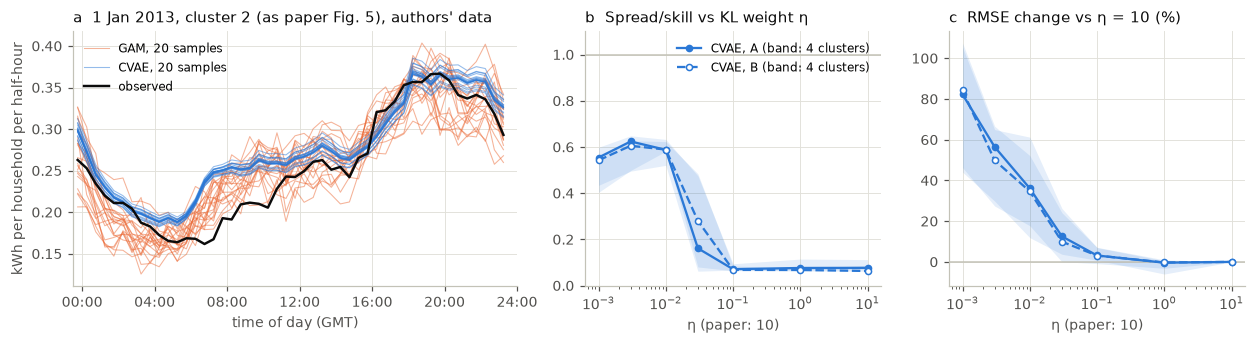

Per eta: share of the 40 models with an active latent unit; seed medians, min-max over the 8 track x cluster cells
        share_with_active_latent  spread_skill_min  spread_skill_max  rmse_change_min  rmse_change_max
eta                                                                                                   
10.000                      0.00              0.06              0.11             0.00             0.00
1.000                       0.00              0.06              0.11            -5.97             1.01
0.100                       0.00              0.06              0.09            -0.85             7.16
0.030                       0.68              0.06              0.48             0.09            26.24
0.010                       1.00              0.52              0.63            11.91            61.25
0.003                       1.00              0.50              0.65            27.45            66.61
0.001                       1.00              0.40           

In [ ]:
te = pd.read_feather("data/authors/test_nmf.feather").assign(date=lambda d: pd.to_datetime(d["date"]))
day0 = pd.Timestamp(pd.read_csv("outputs/trackA/test_dates.csv")["date"].iloc[0])      # day 0 of the sample arrays
obs = te.loc[(te.cluster == 2) & (te.date == day0), [f"consumption_{h:02d}" for h in range(48)]].to_numpy()[0]
S = {m: np.load(f"outputs/trackA/{m}_samples_c2.npy")[:20, 0] for m in ("cvae", "gam")}
eta = pd.read_csv("outputs/verify/v-collapse/eta_sensitivity.csv")       # 2 tracks x 4 clusters x 7 eta x 5 seeds
g = eta.groupby(["track", "cluster", "eta"])[["spread_skill", "rmse_median_kwh"]].median().reset_index()
g = g.merge(g[g.eta == 10][["track", "cluster", "rmse_median_kwh"]].rename(columns={"rmse_median_kwh": "rmse10"}))
g["rmse_change"] = 100 * (g.rmse_median_kwh / g.rmse10 - 1)

fig, axs = plt.subplots(1, 3, figsize=(11.5, 3.2), gridspec_kw={"width_ratios": [1.5, 1, 1]})
ax = axs[0]
for m, col, lab in (("gam", ORANGE, "GAM, 20 samples"), ("cvae", BLUE, "CVAE, 20 samples")):
    for k in range(20):
        ax.plot(x48, S[m][k], color=col, lw=0.7, alpha=0.5, label=lab if k == 0 else None)
ax.plot(x48, obs, color=INK, lw=1.6, label="observed")
ax.set(xlim=(-0.5, 24), xlabel="time of day (GMT)", ylabel="kWh per household per half-hour")
ax.set_xticks(range(0, 25, 4), [f"{h:02d}:00" for h in range(0, 25, 4)])
ax.set_title(f"a  {day0.day} {day0:%b %Y}, cluster 2 (as paper Fig. 5), authors' data", loc="left", fontsize=10, color=INK)
ax.legend(frameon=False, fontsize=8, loc="upper left")
for ax, col, ref, title in ((axs[1], "spread_skill", 1, "b  Spread/skill vs KL weight η"),
                            (axs[2], "rmse_change", 0, "c  RMSE change vs η = 10 (%)")):
    ax.axhline(ref, color="#c3c2b7", lw=1)
    for t, ls, mfc in (("A", "-", BLUE), ("B", "--", "white")):
        s = g[g.track == t].groupby("eta")[col]
        ax.fill_between(s.median().index, s.min(), s.max(), color=BLUE, alpha=0.12, lw=0)
        ax.plot(s.median().index, s.median(), ls, marker="o", ms=4, color=BLUE, mfc=mfc, label=f"CVAE, {t} (band: 4 clusters)")
    ax.set_xscale("log"); ax.set_xlabel("η (paper: 10)"); ax.set_title(title, loc="left", fontsize=10, color=INK)
axs[1].set_ylim(0, 1.1); axs[1].legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()
r = g.groupby("eta").agg(spread_skill_min=("spread_skill", "min"), spread_skill_max=("spread_skill", "max"),
                         rmse_change_min=("rmse_change", "min"), rmse_change_max=("rmse_change", "max"))
r.insert(0, "share_with_active_latent", eta.groupby("eta").active_units.apply(lambda a: (a > 0).mean()))
print("Per eta: share of the 40 models with an active latent unit; seed medians, min-max over the 8 track x cluster cells")
print(r.sort_index(ascending=False).round(2).to_string())
print(f"Max spread/skill over all {len(eta)} models: {eta.spread_skill.max():.2f}")

## 4. Tariff effects: the CVAE's "side effect" is not in the data
- **The scenarios.** We use the windows the paper's Figs. 6 and 8 actually apply: High = slots 39-44 (19:00-22:00 GMT) and Low = slots 9-19 (04:00-09:30 GMT), where slot h is the half-hour ending at h × 30 min. The paper's text ("4:30-9:30", "7:30-10 p.m.") quotes h × 30 min for the first and last slots, so its start times are 30 min late.
- **The model.** As in the paper's Fig. 6, the CVAE starts cutting consumption hours before the High window (a).
- **The data.** Consumption drops exactly when real High blocks start (b) and recovers exactly when they end (c). This is a difference-in-differences against flat-tariff households.
- **Where the CVAE's early drop comes from.** The paper's window almost never appears on its own in training. Most training blocks that contain it are longer, and the CVAE's early drop mirrors them.

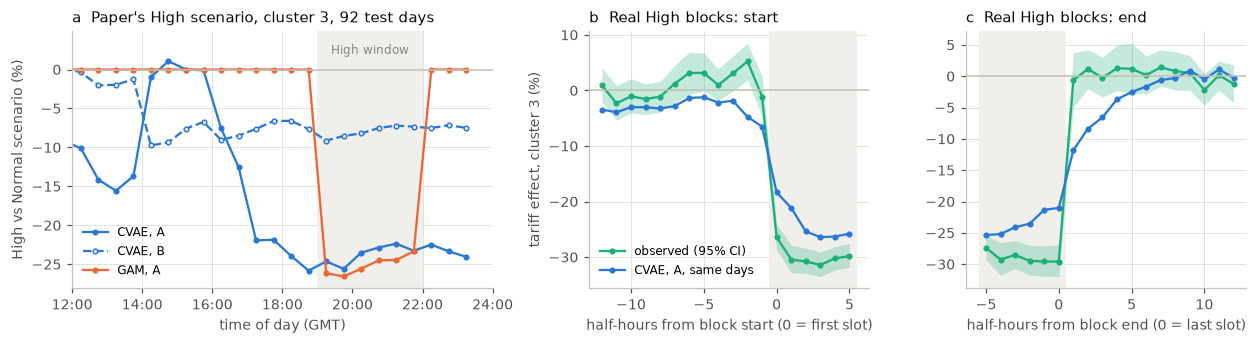

High-tariff effect, % (columns = clusters 0-3):
                                        0     1    2     3
CVAE A, paper scenario   2 h before  -1.7  -9.3 -4.4 -23.4
                         inside      -0.3 -11.0 -5.7 -23.8
                         1.5 h after  0.5 -12.6 -5.8 -23.2
CVAE B, paper scenario   2 h before   3.6  -4.6 -8.8  -7.1
                         inside       3.5  -5.5 -7.4  -8.0
                         1.5 h after  4.7  -5.4 -8.8  -7.4
GAM A, paper scenario    2 h before   0.0   0.0  0.0   0.0
                         inside      -3.4  -5.3 -3.9 -25.2
                         1.5 h after  0.0   0.0  0.0   0.0
data A, real High blocks 2 h before  -0.8  -0.5 -0.3   2.0
                         inside      -4.3  -4.5 -2.5 -29.2
                         2 h after    1.1  -0.0  0.8   0.4

Low-tariff effect, % (columns = clusters 0-3):
                                      0    1    2     3
CVAE A, paper scenario  inside     -2.0  4.8 -5.1  62.4
CVAE B, paper scenario  i

In [ ]:
E = {t: J(f"outputs/track{t}/effects_summary.json") for t in "AB"}
V = J("outputs/verify/v-data/v_data_results.json")
did = V["C_sidefx_DiD_main(K10,Std control)"]
cvd = J("outputs/trackA/mechanism_cvae_same_events.json")["3"]["High"]
fig, axs = plt.subplots(1, 3, figsize=(11.5, 3.2), gridspec_kw={"width_ratios": [1.5, 1, 1]})
ax = axs[0]
ax.axvspan(19, 22, color=SHADE, lw=0); ax.text(20.5, 2, "High window", ha="center", color=MUTED, fontsize=8)
for t, mod, col, ls, mfc, lab in (("A", "cvae", BLUE, "-", BLUE, "CVAE, A"), ("B", "cvae", BLUE, "--", "white", "CVAE, B"),
                                  ("A", "gam", ORANGE, "-", ORANGE, "GAM, A")):
    p = E[t]["profiles"][f"{mod}_c3"]["High"]
    ax.plot(x48, 100 * np.array(p["diff_kwh"]) / np.array(p["normal_kwh"]), ls, marker="o", ms=3, color=col, mfc=mfc, label=lab)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set(xlim=(12, 24), xlabel="time of day (GMT)", ylabel="High vs Normal scenario (%)")
ax.set_xticks(range(12, 25, 2), [f"{h:02d}:00" for h in range(12, 25, 2)])
ax.set_title("a  Paper's High scenario, cluster 3, 92 test days", loc="left", fontsize=10, color=INK)
ax.legend(frameon=False, fontsize=8, loc="lower left")
for ax, key, kcv, title in ((axs[1], "High_start|3", "start_aligned", "b  Real High blocks: start"),
                            (axs[2], "High_end|3", "end_aligned", "c  Real High blocks: end")):
    d = np.array(did["profiles"][key])                       # columns: lag, %, CI low, CI high, n blocks
    lag_m, pct_m = np.array(cvd[kcv]["lags"]), np.array(cvd[kcv]["pct"])
    keep = (d[:, 0] >= lag_m.min()) & (d[:, 0] <= lag_m.max())
    ax.axvspan(-0.5, lag_m.max() + 0.5, color=SHADE, lw=0) if kcv == "start_aligned" else ax.axvspan(lag_m.min() - 0.5, 0.5, color=SHADE, lw=0)
    ax.fill_between(d[keep, 0], d[keep, 2], d[keep, 3], color=AQUA, alpha=0.25, lw=0)
    ax.plot(d[keep, 0], d[keep, 1], "-o", ms=3, color=AQUA, label="observed (95% CI)")
    ax.plot(lag_m, pct_m, "-o", ms=3, color=BLUE, label="CVAE, A, same days")
    ax.axhline(0, color="#c3c2b7", lw=1); ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.set_xlabel("half-hours from block " + ("start (0 = first slot)" if kcv == "start_aligned" else "end (0 = last slot)"))
axs[1].set_ylabel("tariff effect, cluster 3 (%)"); axs[1].legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

R = {}
for t, mod in (("A", "cvae"), ("B", "cvae"), ("A", "gam")):
    reg = E[t]["per_model_cluster"]
    for name, k in (("2 h before", "pre4"), ("inside", "in_window"), ("1.5 h after", "post4")):
        R[(f"{mod.upper()} {t}, paper scenario", name)] = [reg[f"{mod}_c{c}"]["High"]["regions"][k]["pct"] for c in range(4)]
for name, k in (("2 h before", "High_pre_1-4"), ("inside", "High_in"), ("2 h after", "High_post_1-4")):
    R[("data A, real High blocks", name)] = [did["regions"][k][str(c)]["pct"] for c in range(4)]
print("High-tariff effect, % (columns = clusters 0-3):")
print(pd.DataFrame(R, index=range(4)).T.round(1).to_string())
L = {(f"{m.upper()} {t}, paper scenario", "inside"): [E[t]["per_model_cluster"][f"{m}_c{c}"]["Low"]["regions"]["in_window"]["pct"]
                                                     for c in range(4)] for t, m in (("A", "cvae"), ("B", "cvae"), ("A", "gam"))}
for name, k in (("2 h before", "Low_pre_1-4"), ("inside", "Low_in"), ("2 h after", "Low_post_1-4")):
    L[("data A, real Low blocks", name)] = [did["regions"][k][str(c)]["pct"] for c in range(4)]
print("\nLow-tariff effect, % (columns = clusters 0-3):")
print(pd.DataFrame(L, index=range(4)).T.round(1).to_string())

mc = J("outputs/trackA/mechanism_summary.json")["training_context"]
print(f"\nTraining High blocks containing the paper's window 39-44: {mc['n_train_high_runs_containing_39_44']}, of which "
      f"{mc['train_high_runs_exactly_39_44']} is exactly it (" + ", ".join(f"{k} x{v}" for k, v in mc["train_high_runs_containing_39_44"].items()) + ")")
for t in "AB":
    rr = pd.read_csv(f"outputs/track{t}/effects_all_restarts_regions.csv")
    h3 = rr.query("cluster == 3")["High:in_window:pct"]
    lo = rr.groupby("cluster")["Low:in_window:pct"].median()
    print(f"CVAE {t}, 50 training runs per cluster: cl. 3 High median {h3.median():.1f}% (10th-90th percentile "
          f"{h3.quantile(.1):.1f}% to {h3.quantile(.9):.1f}%); Low median by cluster " + "/".join(f"{v:+.1f}" for v in lo) + "%")
pre = V["C_sidefx_refinements"]["High_pre_1-4 | evening start (16-19h local)"]["3"]
print(f"Data A, cluster 3, 2 h before evening High blocks: {pre['pct']:+.1f}% [{pre['lo']:+.1f}, {pre['hi']:+.1f}], {pre['n_blocks']} blocks")
dr = J("outputs/comparison_AB.json")["tariff_effects"]["data_reference"]
for k in ("Low", "High"):
    print(f"Data, matched-day estimator, {k} inside real blocks, clusters 0-3: " +
          " | ".join(f"{t}: " + "/".join(f"{dr[k]['in_block'][str(c)]['track' + t]['pct']:+.1f}" for c in range(4)) for t in "AB"))
for k, lab in (("High_in", "High, inside"), ("Low_in", "Low, inside"), ("Low_pre_1-4", "Low, 2 h before")):
    print(f"Data A, all ToU households, {lab}: {did['regions'][k]['tou']['pct']:+.1f}% ({did['regions'][k]['tou']['Wh_per_slot']:+.1f} Wh per household per half-hour)")
sch = dr["schedule_vs_households_attribution"]["3"]["High"]
print(f"Cluster 3 High effect on our households: {sch['trackB_our_aggregates_xlsx_schedule']['pct']:.1f}% with Tariffs.xlsx "
      f"vs {sch['our_aggregates_authors_schedule']['pct']:.1f}% with the authors' schedule")
n = pd.read_feather("data/authors/sum_up_nmf.feather").number_clients
print(f"Authors' cluster sizes: {n.tolist()}; cluster 3 = {100 * n.iloc[3] / n.sum():.0f}% of {n.sum():,} ToU households")

## 5. Accuracy under our chronological split
The paper scores on test days drawn at random from 2013, interleaved with its training days; our proposal splits chronologically. Here both models are trained on Jan-Aug (243 days), the CVAE run is chosen on Sep-Oct (best of 20 runs), and they are tested on Nov-Dec (61 days). The temperature PCA and scalings are refitted on training days only (`scripts/50_chrono_split.py`).
- **Accuracy collapses.** Test RMSE is 2.7-4.3× the paper's setup, and every method under-predicts Nov-Dec consumption, by 6-32%: Jan-Aug training does not cover the year-end rise.
- **A naive baseline does better.** Taking the October mean profile of the same day type beats the paper's CVAE in all 8 track × cluster cases and the GAM in 6 of 8.
- **The CVAE's position-in-year input makes it worse.** It extrapolates the spring-to-summer decline into winter; dropping that input cuts the bias by a third to two thirds.
- **Cluster 3's High response weakens too.** The chronologically trained CVAE gives −5% (track A) and −14% (track B), against −27% to −29% for the GAM.

In [ ]:
ch = J("outputs/chrono/chrono_results.json")["tracks"]
rows = []
for t in "AB":
    for c in "0123":
        o = ch[t][c]; ref = o["random_split_reference"]
        rows.append({"track": t, "cluster": int(c), "CVAE": o["cvae_paper"]["rmse_median"], "CVAE no pos_y": o["cvae_no_pos_y"]["rmse_median"],
                     "GAM": o["gam"]["rmse_median"], "naive": o["naive"]["rmse_median"],
                     "paper setup CVAE": ref["cvae_rmse_median"], "paper setup GAM": ref["gam_rmse_median"],
                     "bias CVAE %": o["cvae_paper"]["energy_bias_median_pct"], "bias no pos_y %": o["cvae_no_pos_y"]["energy_bias_median_pct"],
                     "bias GAM %": o["gam"]["energy_bias_median_pct"], "bias naive %": o["naive"]["energy_bias_median_pct"]})
cr = pd.DataFrame(rows).set_index(["track", "cluster"])
print("Nov-Dec test days: median RMSE (kWh) and median daily-energy bias (%); 'paper setup' = random-split models on their Nov-Dec test days (21 per cluster)")
print(cr.round(3).to_string())
print(f"naive beats CVAE in {(cr.naive < cr.CVAE).sum()}/8 and GAM in {(cr.naive < cr.GAM).sum()}/8; "
      f"RMSE ratio chrono/paper setup: CVAE {(cr.CVAE / cr['paper setup CVAE']).min():.1f}-{(cr.CVAE / cr['paper setup CVAE']).max():.1f}x, "
      f"GAM {(cr.GAM / cr['paper setup GAM']).min():.1f}-{(cr.GAM / cr['paper setup GAM']).max():.1f}x")
for t in "AB":
    o = ch[t]["3"]
    print(f"track {t}, cluster 3, paper scenarios on the test days: High {o['cvae_paper']['high_effect_pct']:+.1f}% (chrono CVAE), "
          f"{o['gam']['high_effect_pct']:+.1f}% (chrono GAM), {o['random_split_reference']['cvae_selected_high_effect_pct_on_test_days']:+.1f}% (random-split CVAE); "
          f"Low {o['cvae_paper']['low_effect_pct']:+.1f} / {o['gam']['low_effect_pct']:+.1f} / {o['random_split_reference']['cvae_selected_low_effect_pct_on_test_days']:+.1f}%")

Nov-Dec test days: median RMSE (kWh) and median daily-energy bias (%); 'paper setup' = random-split models on their Nov-Dec test days (21 per cluster)
                CVAE  CVAE no pos_y    GAM  naive  paper setup CVAE  paper setup GAM  bias CVAE %  bias no pos_y %  bias GAM %  bias naive %
track cluster                                                                                                                               
A     0        0.065          0.045  0.054  0.047             0.016            0.014      -20.668          -13.047     -14.047       -15.774
      1        0.088          0.055  0.045  0.051             0.021            0.017      -29.758          -17.771      -5.538       -16.476
      2        0.060          0.028  0.047  0.042             0.017            0.016      -23.494           -8.497     -13.699       -15.112
      3        0.061          0.041  0.064  0.048             0.023            0.021      -24.588          -13.064     -19.952       -16.411
B  

## Takeaways for our project
- **For Step 2, the CVAE's tariff response is the weak point, not its accuracy.**
  - Its mean profiles are as accurate as the paper says (RMSE ≈ 0.02 kWh), and those are what Step 3's emissions cost $\hat C_d$ uses. But that accuracy holds only when test days are interleaved with training days. Under our chronological split (section 5) both models under-predict Nov-Dec by 6-32% and lose to a naive baseline. Two candidate fixes, both untested: drop the position-in-year input, and learn the seasonal level from more data. The raw LCL files have 2012 readings for the trial households, taken before the dynamic tariff started.
  - Its response to a schedule change is unreliable. In clusters 0-2 it depends on the training run and the Low response often has the wrong sign. In cluster 3 the sign is right but the size swings with the run (middle 80% of runs: High −10% to −26% on track A, −4% to −24% on track B), against −24% to −29% in the data.
  - Its "side effects" mirror the longer 2013 tariff blocks that contain the paper's window. The new schedules in our policy menu are exactly where it is weakest.
  - It outputs one mean profile per cluster, so household-level results (such as the distribution of bill changes we plan to report) need a separate model.
- **What the data actually show** (difference-in-differences against flat-tariff households):
  - **High:** the drop stays inside the block, with no early drop and no lingering drop afterwards. Cluster 3 drops −29%, the others −2 to −4%. One shift: cluster 3 uses more in the 2 h before evening High blocks (+8.5%, 9 blocks).
  - **Low:** consumption rises inside the window (cluster 3 +35% with this estimator, +45% with matched days; the others +1 to +4%) and dips in the 2 h before (cluster 3 −6%). Only cluster 3 carries over briefly afterwards.
  - **All ToU households together:** High −7%, Low +7%.
  - A simpler candidate for Step 2 (not tested here): a per-cluster model with per-slot tariff effects plus terms for these edge effects. The paper's GAM already gets the in-window part right, and its mean profiles are 23-26% more accurate than the CVAE's.
- **If we keep the CVAE:**
  - average the response over many training runs instead of keeping the lowest-test-MSE run. This steadies it, but cluster 3's High response stays underestimated and the wrong-sign Low in clusters 1-2 remains;
  - check its response on real tariff blocks (as in section 4) before trusting it for new schedules;
  - restrict candidate schedules to block shapes seen in 2013, which is stricter than the proposal's "plausible price patterns". Even then, expect about 1 h of early drop and 2 h of slow recovery that the data do not show;
  - don't use its samples for uncertainty: they are nearly deterministic.
- **Respondents are concentrated.** Cluster 3 holds 16% of ToU households but most of the response, so model clusters separately. Our re-implementation of the clustering places some households differently (ARI 0.58-0.66 against the authors' partition), but each of our clusters matches one of theirs.
- **Fix the inputs before joining with carbon intensity.**
  - `Tariffs.xlsx` is in London clock time and labels each half-hour by its start; LCL is in GMT and labels each half-hour by its end. Put tariffs, consumption and carbon intensity on one convention before joining; `lib.tariffs.select_tariff_version(df, "loc")` does it for the xlsx.
  - The xlsx's late-2013 schedule has errors: 11 extra event days show no response (`outputs/verify/v-data/`). The authors' prepared data use the better-supported schedule: consumption favours it on 15 of the 17 disputed days, though its own extra Low blocks on 29-30 Dec show no response either. Using the xlsx weakens cluster 3's measured High response (−24% vs −28%).